# Experimento 2 — Lei dos Grandes Números
**Máquina Estatística — Probabilidade e Estatística I (IFES Serra - 2026/2)**  
**Equipe:** João Victor Santos Araujo & João Victor Nascimento Ribeiro  
**Professor:** Fidelis Zanetti de Castro  

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/joaovictorsaraujo/maquina-estatistica/blob/master/notebooks/02_convergencia_medias.ipynb)

---
### Descrição do Experimento
Simulação de Monte Carlo com três sementes (10, 2026, 123456) para N = 100, 1.000 e 10.000 rodadas, e verificação de reprodutibilidade determinística.


In [1]:
# Configuração de ambiente para Google Colab e ambiente local
import sys
from pathlib import Path

# Se executando no Google Colab, clona o repositório para obter tabelas e resultados
if 'google.colab' in sys.modules:
    if not Path('resultados/tabelas').is_dir():
        !git clone https://github.com/joaovictorsaraujo/maquina-estatistica.git
        %cd maquina-estatistica

try:
    from IPython.display import display
except ImportError:
    display = print

from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Procura a raiz do projeto a partir de notebooks/, src/ ou da própria raiz.
caminho_atual = Path.cwd().resolve()
raiz = next(
    (
        pasta for pasta in (caminho_atual, *caminho_atual.parents)
        if (pasta / "resultados" / "tabelas" / "e2_medias_acumuladas.csv").is_file()
    ),
    None,
)

if raiz is None:
    raise FileNotFoundError(
        "Não encontrei resultados/tabelas/e2_medias_acumuladas.csv. "
        "Abra o notebook dentro do repositório que já contém os resultados exportados."
    )

arquivo_medias = raiz / "resultados" / "tabelas" / "e2_medias_acumuladas.csv"
arquivo_reprodutibilidade = raiz / "resultados" / "tabelas" / "e2_reprodutibilidade_10_primeiros.csv"
arquivo_json = raiz / "resultados" / "dados_oficiais.json"
arquivo_e1_resumo = raiz / "resultados" / "tabelas" / "e1_metricas_resumo.csv"
pasta_graficos = raiz / "resultados" / "graficos" / "notebooks"
pasta_graficos.mkdir(parents=True, exist_ok=True)

for caminho in [arquivo_medias, arquivo_reprodutibilidade, arquivo_json]:
    if not caminho.is_file():
        raise FileNotFoundError(f"Arquivo necessário não encontrado: {caminho}")

print("Raiz do projeto:", raiz)
print("Tabela E2:", arquivo_medias)
print("Reprodutibilidade:", arquivo_reprodutibilidade)
print("Curvas amostradas:", arquivo_json)
print("Gráficos serão salvos em:", pasta_graficos)

Raiz do projeto: C:\Users\João Vitor\Downloads\maquina-estatistica-master (1)\maquina-estatistica-master
Tabela E2: C:\Users\João Vitor\Downloads\maquina-estatistica-master (1)\maquina-estatistica-master\resultados\tabelas\e2_medias_acumuladas.csv
Reprodutibilidade: C:\Users\João Vitor\Downloads\maquina-estatistica-master (1)\maquina-estatistica-master\resultados\tabelas\e2_reprodutibilidade_10_primeiros.csv
Curvas amostradas: C:\Users\João Vitor\Downloads\maquina-estatistica-master (1)\maquina-estatistica-master\resultados\dados_oficiais.json
Gráficos serão salvos em: C:\Users\João Vitor\Downloads\maquina-estatistica-master (1)\maquina-estatistica-master\resultados\graficos\notebooks


In [2]:
df_medias = pd.read_csv(arquivo_medias)

colunas_obrigatorias = {"seed", "rodadas_acumuladas", "media_acumulada_lucro"}
assert colunas_obrigatorias.issubset(df_medias.columns), "Faltam colunas no CSV do E2."

df_medias["seed"] = pd.to_numeric(df_medias["seed"], errors="raise").astype(int)
df_medias["rodadas_acumuladas"] = pd.to_numeric(df_medias["rodadas_acumuladas"], errors="raise").astype(int)
df_medias["media_acumulada_lucro"] = pd.to_numeric(df_medias["media_acumulada_lucro"], errors="raise")

sementes = [10, 2026, 123456]
pontos_conferencia = [100, 1000, 10000]
esperanca_teorica = -0.16

assert len(df_medias) == 9, "Esperadas 9 linhas: 3 sementes × 3 pontos de conferência."
assert set(df_medias["seed"]) == set(sementes), "Sementes diferentes das especificadas."
assert set(df_medias["rodadas_acumuladas"]) == set(pontos_conferencia)
assert not df_medias.duplicated(["seed", "rodadas_acumuladas"]).any()

# Tabela 3×3 pedida pelo professor.
tabela_medias = (
    df_medias.pivot(index="seed", columns="rodadas_acumuladas", values="media_acumulada_lucro")
    .loc[sementes, pontos_conferencia]
)
tabela_medias.index.name = "Semente"
tabela_medias.columns.name = "Número de rodadas"

print("Média acumulada do lucro líquido (créditos por rodada):")
display(tabela_medias.style.format("{:+.4f}"))

Média acumulada do lucro líquido (créditos por rodada):


Número de rodadas,100,1000,10000
Semente,,,
10,-0.7000,-0.0550,-0.0960
2026,+0.2000,-0.2200,-0.1315
123456,+0.2000,-0.0700,-0.2215


In [3]:
with arquivo_json.open("r", encoding="utf-8") as f:
    dados_oficiais = json.load(f)

dados_e2 = dados_oficiais["e2"]
x_rodadas = np.asarray(dados_e2["pontos_x"], dtype=int)
curvas = {
    seed: np.asarray(dados_e2["curvas"][str(seed)], dtype=float)
    for seed in sementes
}

assert x_rodadas.ndim == 1 and len(x_rodadas) > 0
assert np.all(np.diff(x_rodadas) > 0), "Os números de rodadas devem ser crescentes."
assert x_rodadas[-1] == 10000, "A última observação precisa corresponder a 10.000 rodadas."
assert all(len(curvas[seed]) == len(x_rodadas) for seed in sementes)
assert np.isfinite(np.concatenate(list(curvas.values()))).all()

print(f"Pontos registrados por trajetória: {len(x_rodadas)}")
print(f"Primeira rodada representada: {x_rodadas[0]}")
print(f"Última rodada representada: {x_rodadas[-1]}")
print(f"Passos observados: {np.unique(np.diff(x_rodadas))}")

Pontos registrados por trajetória: 200
Primeira rodada representada: 50
Última rodada representada: 10000
Passos observados: [50]


In [4]:
# Os valores do JSON foram arredondados na exportação. A tolerância
# de 0,0001 evita falsos erros por arredondamento decimal.
for seed in sementes:
    for n in pontos_conferencia:
        posicoes = np.flatnonzero(x_rodadas == n)
        assert len(posicoes) == 1, f"Ponto n={n} ausente ou duplicado na curva."
        valor_curva = curvas[seed][int(posicoes[0])]
        valor_csv = float(tabela_medias.loc[seed, n])
        assert np.isclose(valor_curva, valor_csv, atol=1e-4, rtol=0), (
            f"Divergência para seed={seed}, n={n}: JSON={valor_curva} × CSV={valor_csv}"
        )

# O valor da semente 2026 em 10.000 rodadas deve coincidir com o E1.
if arquivo_e1_resumo.is_file():
    resumo_e1 = pd.read_csv(arquivo_e1_resumo)
    valores_e1 = resumo_e1.set_index("metrica")["valor"]
    lucro_e1 = float(valores_e1.loc["Lucro médio observado (créditos)"])
    assert np.isclose(tabela_medias.loc[2026, 10000], lucro_e1, atol=1e-6)
    print("Conferência E1 × E2 (semente 2026): OK")

print("Conferência JSON × CSV (3 sementes, 3 pontos): OK")

Conferência E1 × E2 (semente 2026): OK
Conferência JSON × CSV (3 sementes, 3 pontos): OK


In [5]:
df_reprodutibilidade = pd.read_csv(arquivo_reprodutibilidade)

assert len(df_reprodutibilidade) == 10, "O enunciado solicita os 10 primeiros resultados."
assert set(["rodada", "original_paradas", "original_comb", "repeticao_paradas", "repeticao_comb", "coincidem"]).issubset(df_reprodutibilidade.columns)
assert df_reprodutibilidade["rodada"].tolist() == list(range(1, 11))

# Confere os registros exportados. Não realiza uma nova execução do gerador.
mesmas_paradas = (df_reprodutibilidade["original_paradas"].astype(str)
                  == df_reprodutibilidade["repeticao_paradas"].astype(str))
mesmas_combinacoes = (df_reprodutibilidade["original_comb"].astype(str)
                      == df_reprodutibilidade["repeticao_comb"].astype(str))
conferidas = df_reprodutibilidade["coincidem"].astype(str).str.lower().eq("true")

assert (mesmas_paradas & mesmas_combinacoes & conferidas).all(), "Há divergências na verificação exportada."

print("Dez primeiros resultados da semente 2026: correspondência confirmada no CSV.")
display(df_reprodutibilidade[["rodada", "original_paradas", "original_comb", "coincidem"]])

Dez primeiros resultados da semente 2026: correspondência confirmada no CSV.


,rodada,original_paradas,original_comb,coincidem
0,1,"(0, 2, 4)",B-D-A,True
1,2,"(4, 0, 1)",A-B-C,True
2,3,"(4, 4, 4)",A-A-A,True
3,4,"(3, 4, 4)",E-A-A,True
4,5,"(3, 4, 3)",E-A-E,True
5,6,"(1, 0, 4)",C-B-A,True
6,7,"(0, 0, 2)",B-B-D,True
7,8,"(0, 3, 0)",B-E-B,True
8,9,"(3, 2, 1)",E-D-C,True
9,10,"(3, 2, 2)",E-D-D,True


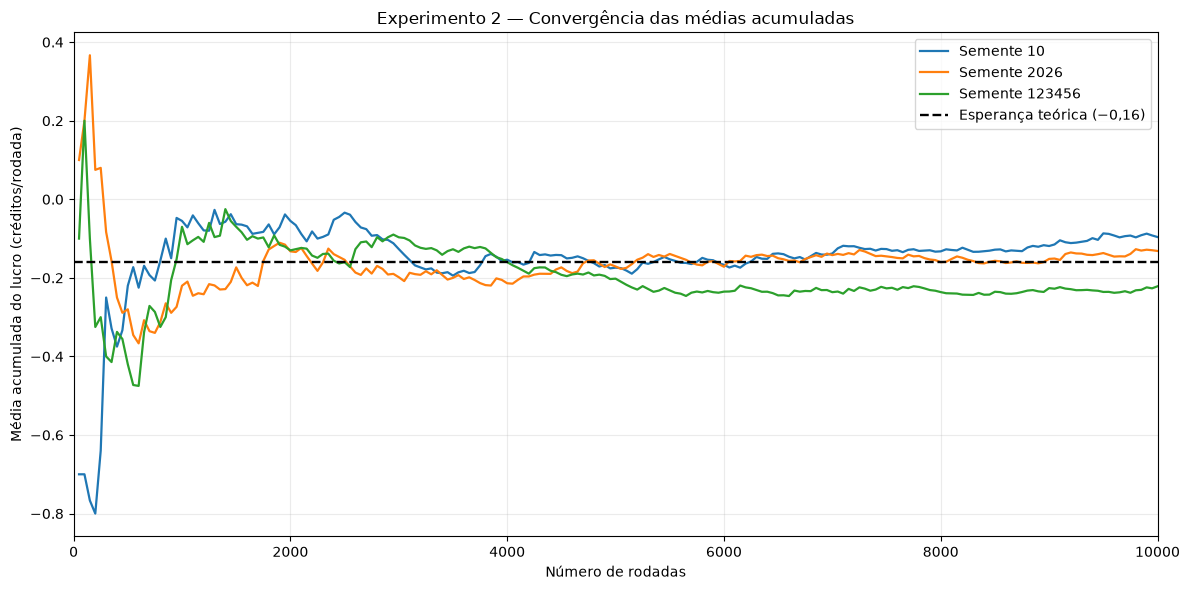

Gráfico salvo em: C:\Users\João Vitor\Downloads\maquina-estatistica-master (1)\maquina-estatistica-master\resultados\graficos\notebooks\e2_convergencia_medias_notebook.png


In [6]:
fig, ax = plt.subplots(figsize=(12, 6))

for seed in sementes:
    ax.plot(x_rodadas, curvas[seed], label=f"Semente {seed}", linewidth=1.6)

ax.axhline(
    esperanca_teorica,
    color="black",
    linestyle="--",
    linewidth=1.7,
    label="Esperança teórica (−0,16)",
)

ax.set_title("Experimento 2 — Convergência das médias acumuladas")
ax.set_xlabel("Número de rodadas")
ax.set_ylabel("Média acumulada do lucro (créditos/rodada)")
ax.set_xlim(0, 10000)
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()

caminho_figura_1 = pasta_graficos / "e2_convergencia_medias_notebook.png"
fig.savefig(caminho_figura_1, dpi=200, bbox_inches="tight")
plt.show()
print("Gráfico salvo em:", caminho_figura_1)

Distância absoluta da média observada à esperança teórica:


Número de rodadas,100,1000,10000
Semente,,,
10,0.5400,0.1050,0.0640
2026,0.3600,0.0600,0.0285
123456,0.3600,0.0900,0.0615


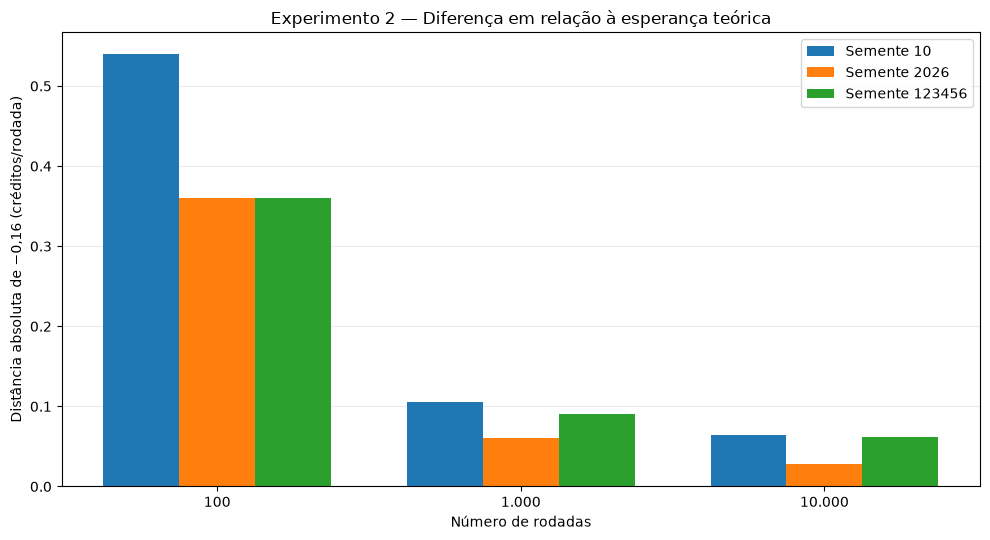

Gráfico salvo em: C:\Users\João Vitor\Downloads\maquina-estatistica-master (1)\maquina-estatistica-master\resultados\graficos\notebooks\e2_distancia_esperanca_notebook.png


In [7]:
erros_absolutos = (tabela_medias - esperanca_teorica).abs()
print("Distância absoluta da média observada à esperança teórica:")
display(erros_absolutos.style.format("{:.4f}"))

fig, ax = plt.subplots(figsize=(10, 5.5))
indices = np.arange(len(pontos_conferencia))
largura = 0.25

for i, seed in enumerate(sementes):
    valores = erros_absolutos.loc[seed, pontos_conferencia].to_numpy(dtype=float)
    ax.bar(indices + (i - 1) * largura, valores, largura, label=f"Semente {seed}")

ax.set_xticks(indices, [f"{n:,}".replace(",", ".") for n in pontos_conferencia])
ax.set_xlabel("Número de rodadas")
ax.set_ylabel("Distância absoluta de −0,16 (créditos/rodada)")
ax.set_title("Experimento 2 — Diferença em relação à esperança teórica")
ax.legend()
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
fig.tight_layout()

caminho_figura_2 = pasta_graficos / "e2_distancia_esperanca_notebook.png"
fig.savefig(caminho_figura_2, dpi=200, bbox_inches="tight")
plt.show()
print("Gráfico salvo em:", caminho_figura_2)

In [8]:
print("Referência teórica: E[X] = −0,16 crédito por rodada")
print("Sequências avaliadas: 3, com 10.000 rodadas cada")
print("Sementes: 10, 2026 e 123456")
print()

for seed in sementes:
    inicio = tabela_medias.loc[seed, 100]
    meio = tabela_medias.loc[seed, 1000]
    final = tabela_medias.loc[seed, 10000]
    erro_final = abs(final - esperanca_teorica)
    print(
        f"Seed {seed:>6}: "
        f"N=100: {inicio:+.4f} | N=1.000: {meio:+.4f} | "
        f"N=10.000: {final:+.4f} | Erro final: {erro_final:.4f}"
    )

print("\nAs médias são amostrais e não precisam ser iguais à esperança em 10.000 rodadas.")
print("Os gráficos utilizam resultados previamente exportados, sem novos sorteios.")

Referência teórica: E[X] = −0,16 crédito por rodada
Sequências avaliadas: 3, com 10.000 rodadas cada
Sementes: 10, 2026 e 123456

Seed     10: N=100: -0.7000 | N=1.000: -0.0550 | N=10.000: -0.0960 | Erro final: 0.0640
Seed   2026: N=100: +0.2000 | N=1.000: -0.2200 | N=10.000: -0.1315 | Erro final: 0.0285
Seed 123456: N=100: +0.2000 | N=1.000: -0.0700 | N=10.000: -0.2215 | Erro final: 0.0615

As médias são amostrais e não precisam ser iguais à esperança em 10.000 rodadas.
Os gráficos utilizam resultados previamente exportados, sem novos sorteios.
